PART-A

In [1]:
import pandas as pd                     # library for tables
import matplotlib.pyplot as plt         # library for charts

df_raw = pd.read_csv("sales_raw.csv")   # read the file into a table
df_raw.head()                           # first 5 rows

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


In [2]:
print(df_raw.shape)                     # (rows, columns)
print(list(df_raw.columns))             # column names
print(df_raw.dtypes)                    # data type of each column

(21, 6)
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']
transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object


In [3]:
print(df_raw.isna().sum())              # missing values per column
print(df_raw.duplicated().sum())        # number of duplicate rows

transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64
1


In [4]:
# clean data
df = df_raw.copy()   
rows_before = len(df)

In [5]:
for col in ["region", "category"]:
    df[col] = df[col].str.strip().str.title()

In [6]:
df["region"] = df["region"].fillna("Unknown")

In [7]:
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["sale_date"] = pd.to_datetime(df["sale_date"], format="%m/%d/%Y", errors="coerce")

In [8]:
df = df.drop_duplicates()

In [9]:
df = df.dropna(subset=["quantity", "unit_price"])   # missing values
df = df[df["quantity"] > 0]                         # removes the -2
df = df[df["unit_price"] > 0]
df = df[df["unit_price"] <= 1000]                   # removes the 10000 outlier

In [10]:
df["quantity"] = df["quantity"].astype(int)
df = df.reset_index(drop=True)

print("Before:", rows_before)     # 21
print("After:", len(df))          # 15

Before: 21
After: 15


In [11]:
df["revenue"] = df["quantity"] * df["unit_price"]

In [12]:
region_summary = df.groupby("region")["revenue"].sum().sort_values(ascending=False)
category_summary = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(region_summary)
print(category_summary)

region
North      1470.0
West       1130.0
South      1035.0
East        740.0
Unknown     400.0
Name: revenue, dtype: float64
category
Books         2370.0
Food          1945.0
Stationery     460.0
Name: revenue, dtype: float64


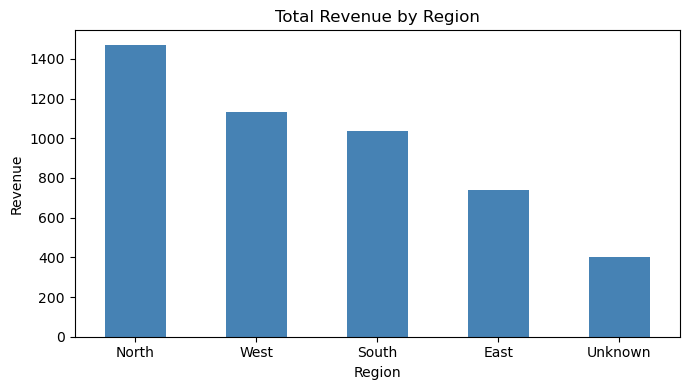

In [13]:
plt.figure(figsize=(7, 4))
region_summary.plot(kind="bar", color="steelblue")
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart_revenue_by_region.png")
plt.show()

In [14]:
df.to_csv("cleaned_sales.csv", index=False)

PART-B

In [15]:
df_b = pd.read_csv("cleaned_sales.csv")
df_b["tax_amount"] = df_b["revenue"] * 0.05
df_b.head()

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2,250.0,500.0,25.0


In [16]:
df_b.loc[df_b["category"] == "Books", "unit_price"] *= 1.10

In [17]:
df_b["revenue"] = df_b["quantity"] * df_b["unit_price"]
df_b["tax_amount"] = df_b["revenue"] * 0.05

In [18]:
df_b = df_b[df_b["transaction_id"] != 1015]

In [19]:
df_b["review_status"] = "pending"
df_b = df_b.drop(columns=["review_status"])

In [21]:
df_b.to_csv("sales_updated.csv", index=False)

check = pd.read_csv("sales_updated.csv")
print(check.head())
print(list(check.columns))

   transaction_id   sale_date region    category  quantity  unit_price  \
0            1001  2026-10-01  North        Food         2       120.0   
1            1002  2026-10-01  South       Books         1       275.0   
2            1003  2026-10-02  North        Food         3       110.0   
3            1004  2026-10-02   East  Stationery         4        50.0   
4            1005  2026-10-03  South       Books         2       275.0   

   revenue  tax_amount  
0    240.0       12.00  
1    275.0       13.75  
2    330.0       16.50  
3    200.0       10.00  
4    550.0       27.50  
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
